In [1]:
from pathlib import Path 
import numpy as np
import pandas as pd
import matplotlib. pyplot as plt

In [2]:
file_path = "data_cleaned.csv"

df = pd.read_csv(file_path, low_memory=False)


In [3]:
df[
    ["country_name", "weight", "is_young",
     "ai_heard_alot", "ai_is_excited"]
].head()


,country_name,weight,is_young,ai_heard_alot,ai_is_excited
0,Canada,0.592005,False,0.0,0.0
1,Canada,0.446814,False,0.0,0.0
2,Canada,1.120110,False,0.0,0.0
3,Canada,0.695317,False,0.0,0.0
4,Canada,0.369352,False,1.0,0.0


In [4]:

print("Age Grouping:")
print(df["is_young"].value_counts(dropna=False))

print("\nAI cognitive indicators:")
print(df["ai_heard_alot"].value_counts(dropna=False))

print("\nAI optimism indicator:")
print(df["ai_is_excited"].value_counts(dropna=False))


Age Grouping:
False    21984
True      6053
NaN        296
Name: is_young, dtype: int64

AI cognitive indicators:
0.0    18118
1.0     9407
NaN      808
Name: ai_heard_alot, dtype: int64

AI optimism indicator:
0.0    21661
1.0     4708
NaN     1964
Name: ai_is_excited, dtype: int64


In [5]:

awareness_data = df.loc[
    df["is_young"].notna()
    & df["ai_heard_alot"].notna()
    & df["weight"].notna()
    & df["weight"].gt(0)
].copy()

# Calculate weighted percentages by country and age group
rows = []

for (country, young), group in awareness_data.groupby(
    ["country_name", "is_young"]
):
    percentage = (
        (group["ai_heard_alot"] * group["weight"]).sum()
        / group["weight"].sum()
        * 100
    )

    rows.append({
        "country": country,
        "is_young": young,
        "n": len(group),
        "awareness_pct": percentage
    })

awareness_summary = pd.DataFrame(rows)


awareness_summary.head(6)

,country,is_young,n,awareness_pct
0,Argentina,False,763,18.974297
1,Argentina,True,236,38.578284
2,Australia,False,1500,38.128820
3,Australia,True,325,66.963638
4,Brazil,False,831,16.535563
5,Brazil,True,210,38.743667


In [6]:

awareness_gap = awareness_summary.pivot(
    index="country",
    columns="is_young",
    values="awareness_pct"
)

# named
awareness_gap = awareness_gap.rename(columns={
    False: "age_30_plus_pct",
    True: "age_18_29_pct"
})

# younger minus older adults
awareness_gap["gap_pp"] = (
    awareness_gap["age_18_29_pct"]
    - awareness_gap["age_30_plus_pct"]
)


awareness_gap = awareness_gap.sort_values(
    "gap_pp", ascending=False
)


awareness_gap.head().round(2)

is_young,age_30_plus_pct,age_18_29_pct,gap_pp
country,,,
Greece,27.51,74.88,47.37
South Korea,15.20,56.23,41.04
Poland,28.28,65.97,37.70
Japan,47.46,81.63,34.16
Spain,25.70,57.94,32.24


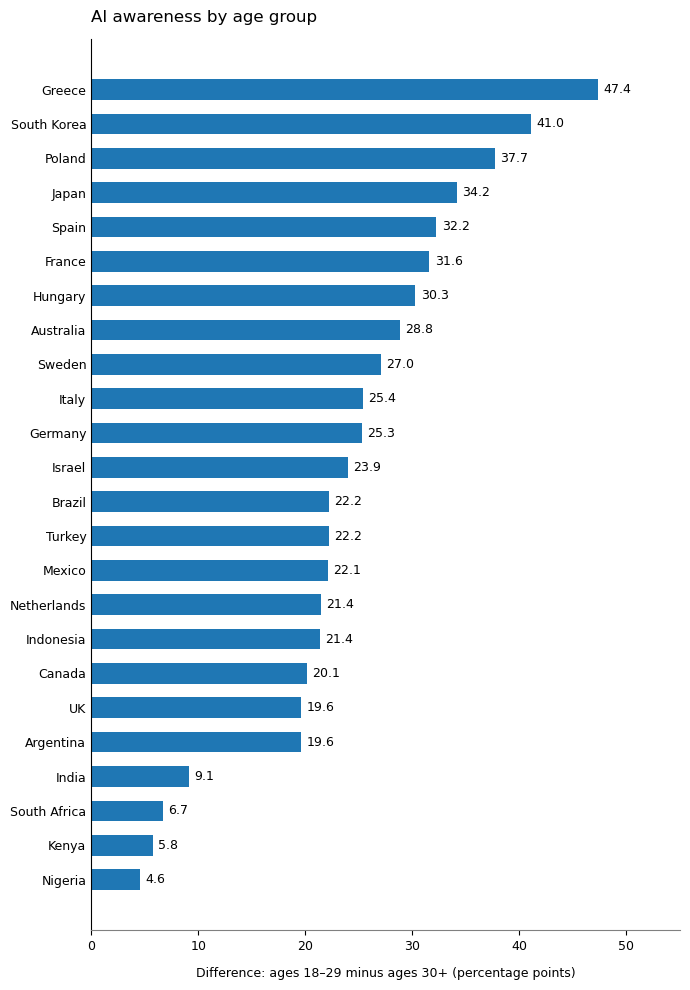

In [7]:
plot_data = awareness_gap.sort_values("gap_pp")

with plt.style.context("default"):

    fig, ax = plt.subplots(figsize=(7, 10))

    
    ax.barh(
        plot_data.index,
        plot_data["gap_pp"],
        height=0.6
    )

    
    for i, gap in enumerate(plot_data["gap_pp"]):
        ax.text(
            gap + 0.5,
            i,
            f"{gap:.1f}",
            va="center",
            fontsize=9
        )

    ax.set_title(
        "AI awareness by age group",
        fontsize=12,
        loc="left",
        pad=12
    )

    ax.set_xlabel(
        "Difference: ages 18–29 minus ages 30+ (percentage points)",
        fontsize=9,
        labelpad=10
    )

    
    ax.set_xlim(0, 55)
    ax.set_xticks(range(0, 51, 10))

    
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    #ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("0.5")

    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    ax.grid(False)
    ax.tick_params(axis="y", length=0, labelsize=9)
    ax.tick_params(axis="x", labelsize=9)

    fig.tight_layout()

    fig.savefig("awareness_gap.png", dpi=300, bbox_inches="tight")
    plt.show()  


    plt.show()


In [8]:
optimism_data = df.loc[
    df["is_young"].notna()
    & df["ai_is_excited"].notna()
    & df["weight"].notna()
    & df["weight"].gt(0)
].copy()

rows = []

for (country, young), group in optimism_data.groupby(
    ["country_name", "is_young"]
):
    percentage = (
        (group["ai_is_excited"] * group["weight"]).sum()
        / group["weight"].sum()
        * 100
    )

    rows.append({
        "country": country,
        "is_young": young,
        "n": len(group),
        "optimism_pct": percentage
    })

optimism_summary = pd.DataFrame(rows)

# reshape 
optimism_gap = optimism_summary.pivot(
    index="country",
    columns="is_young",
    values="optimism_pct"
).rename(columns={
    False: "age_30_plus_pct",
    True: "age_18_29_pct"
})

# younger minus older adults
optimism_gap["gap_pp"] = (
    optimism_gap["age_18_29_pct"]
    - optimism_gap["age_30_plus_pct"]
)

optimism_gap = optimism_gap.sort_values(
    "gap_pp", ascending=False
)

optimism_gap.round(2)

is_young,age_30_plus_pct,age_18_29_pct,gap_pp
country,,,
Israel,26.91,53.38,26.46
Spain,16.68,37.45,20.77
Italy,9.74,27.50,17.76
Poland,13.18,30.73,17.54
Netherlands,14.07,27.43,13.36
Japan,14.70,26.44,11.73
South Korea,20.84,32.13,11.29
Argentina,11.13,21.29,10.17
Canada,7.32,17.06,9.75


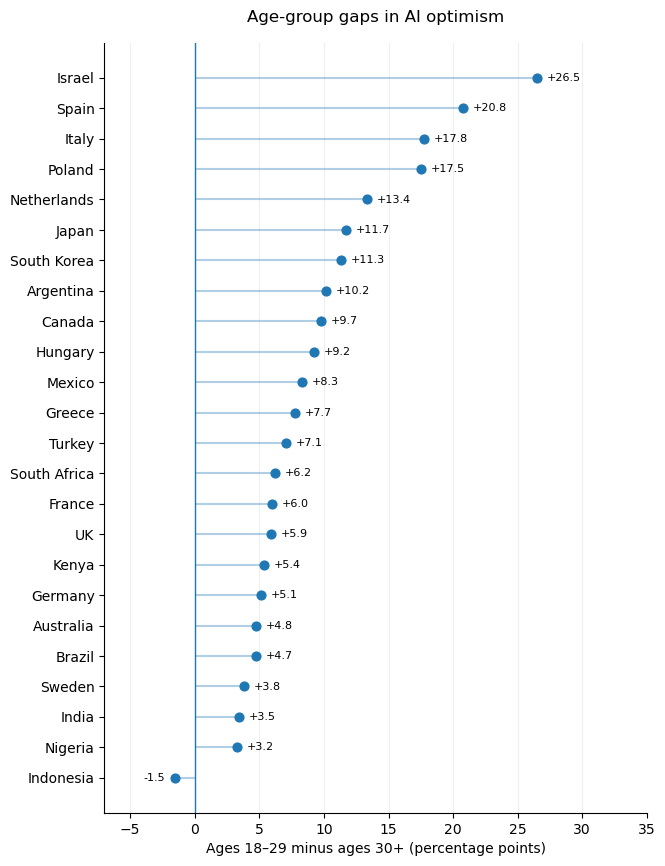

In [9]:
# Sort countries by the optimism gap
plot_data = optimism_gap.sort_values("gap_pp")

fig, ax = plt.subplots(figsize=(7, 10))

ax.hlines(
    y=plot_data.index,
    xmin=0,
    xmax=plot_data["gap_pp"],
    alpha=0.35
)

ax.scatter(
    plot_data["gap_pp"],
    plot_data.index,
    s=40,
    zorder=3
)


for country, gap in plot_data["gap_pp"].items():
    ax.annotate(
        f"{gap:+.1f}",
        xy=(gap, country),
        xytext=(7 if gap >= 0 else -7, 0),
        textcoords="offset points",
        va="center",
        ha="left" if gap >= 0 else "right",
        fontsize=8
    )

ax.set_title(
    "Age-group gaps in AI optimism",
    pad=15
)

ax.set_xlabel(
    "Ages 18–29 minus ages 30+ (percentage points)"
)

ax.set_xlim(-7, 35)
ax.axvline(0, linewidth=1)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

fig.savefig("optimism_gap.png", dpi=300, bbox_inches="tight")
plt.show()

fig.tight_layout()
plt.show()
